# Scénario S6 : HHAR, des montres aux téléphones

**La question.** Un modèle de reconnaissance d'activité a été appris sur des **montres connectées** (la source). On veut maintenant le faire marcher sur des **téléphones** portés à la taille (la cible), pour des utilisateurs qu'il n'a jamais vus, et l'on n'y a étiqueté que quelques dizaines à quelques centaines de fenêtres de 2 secondes. Le savoir appris sur les montres aide-t-il ? Avec quelles méthodes, et jusqu'à quel budget d'annotation ?

**Comment lire ce notebook.** Il ne relance pas l'expérience : il lit les résultats écrits par le moteur. Pour les produire, depuis la racine du dépôt :

```bash
python -m transfer_forest.run S6      # 20 graines, 11 méthodes, 5 budgets
```

La section 6 refait quelques apprentissages (environ 20 s). La section 7 compare S6 à S1 : elle demande aussi `python -m transfer_forest.run S1`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.model_selection import train_test_split

from transfer_forest.contracts import make_forest
from transfer_forest.data import load_scenarios
from transfer_forest.data.s6_hhar import load_windows
from transfer_forest.splits import TEST_SEED, split_target

RESULTS = Path("..") / "results"      # écrit par : python -m transfer_forest.run S6 (depuis la racine)
results = pd.read_csv(RESULTS / "S6.csv")
summary = pd.read_csv(RESULTS / "S6_summary.csv")
timing = pd.read_csv(RESULTS / "S6_timing.csv", index_col=0)

[scn] = load_scenarios("S6")
windows = load_windows()
reserve, test = split_target(scn)
users = np.array(scn.params["users"])
print(f"source : {scn.n_S} fenêtres, {len(scn.params['source_devices'])} montres   "
      f"cible : {len(scn.yt)} fenêtres, {len(scn.params['target_devices'])} téléphones, {len(users)} utilisateurs")
print(f"réserve : {len(reserve)} fenêtres, utilisateurs {', '.join(users[np.unique(scn.groups_t[reserve])])}   "
      f"test : {len(test)} fenêtres, utilisateurs {', '.join(users[np.unique(scn.groups_t[test])])}")

source : 7521 fenêtres, 4 montres   cible : 35175 fenêtres, 6 téléphones, 9 utilisateurs
réserve : 15191 fenêtres, utilisateurs b, c, f, h   test : 19984 fenêtres, utilisateurs a, d, e, g, i


## 1. Le scénario

Le jeu HHAR (UCI n° 344) contient l'accéléromètre et le gyroscope de montres et de téléphones portés par 9 personnes qui font 6 activités : vélo, assis, debout, marche, monter et descendre des escaliers. Une forêt ne lit pas des mesures brutes : on les résume en **fenêtres de 2 secondes**, avec 32 variables (moyenne, écart-type, min et max de x, y, z et de la norme, pour chaque capteur).

- **Source** : les montres (LG Watch et Gear), 7 521 fenêtres.
- **Cible** : les téléphones (Nexus 4, Galaxy S3 et S3 mini), 35 175 fenêtres. Les Galaxy S+ n'ont pas de gyroscope : ils sont écartés.
- **Pourquoi ce sens** : l'inverse (téléphones vers montres) est impossible avec le protocole : le plus gros budget (20 % de la source) dépasserait la réserve de la cible.
- **Note principale : l'erreur.** Les six classes sont à peu près équilibrées, il n'y a pas de classe critique.
- **Découpage par utilisateur** : chaque personne va entière dans le test ou dans la réserve. Sinon, une méthode serait notée sur des fenêtres presque identiques à celles qu'elle a apprises (section 6).

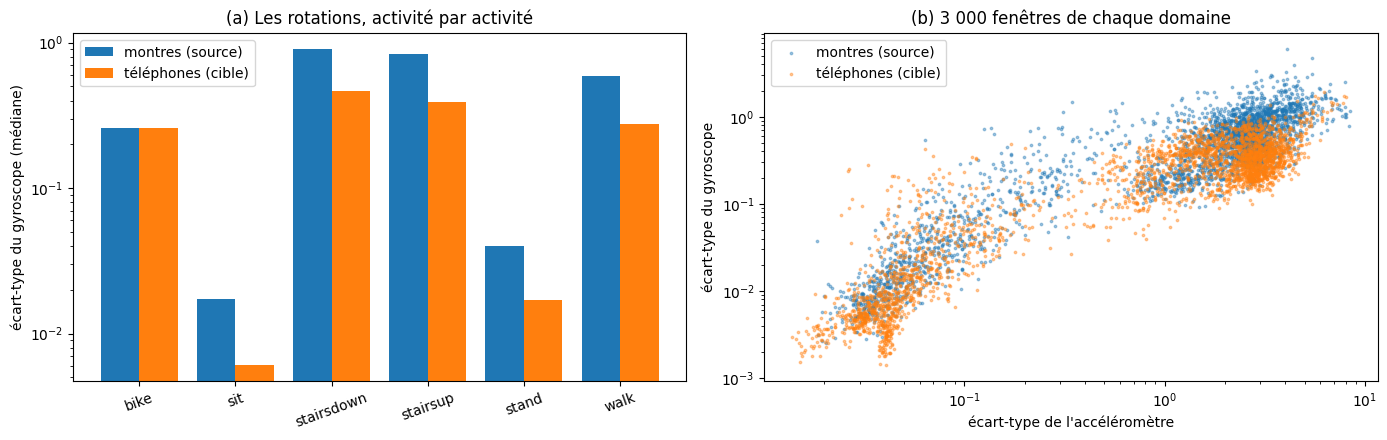

médiane de l'écart-type du gyroscope, rapport téléphone / montre :
label
bike          0.99
sit           0.35
stairsdown    0.51
stairsup      0.47
stand         0.42
walk          0.47


In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
med = windows.pivot_table(index="label", columns="device_type", values="gyro_m_std", aggfunc="median")
x = np.arange(len(med))
ax1.bar(x - 0.2, med["watch"], 0.4, label="montres (source)")
ax1.bar(x + 0.2, med["phone"], 0.4, label="téléphones (cible)")
ax1.set_xticks(x, med.index, rotation=20)
ax1.set(yscale="log", ylabel="écart-type du gyroscope (médiane)", title="(a) Les rotations, activité par activité")
ax1.legend()

for kind, color in [("watch", "C0"), ("phone", "C1")]:
    d = windows[windows.device_type == kind].sample(3000, random_state=0)
    ax2.scatter(d.acc_m_std, d.gyro_m_std, s=3, alpha=0.4, color=color,
                label="montres (source)" if kind == "watch" else "téléphones (cible)")
ax2.set(xscale="log", yscale="log", xlabel="écart-type de l'accéléromètre", ylabel="écart-type du gyroscope",
        title="(b) 3 000 fenêtres de chaque domaine")
ax2.legend()
plt.tight_layout()
plt.show()

print("médiane de l'écart-type du gyroscope, rapport téléphone / montre :")
print((med["phone"] / med["watch"]).round(2).to_string())

**(a)** Pour la marche et les escaliers, le gyroscope mesure environ **deux fois plus de rotation** sur une montre que sur un téléphone (rapport de 0,47 à 0,51) : le poignet tourne beaucoup plus que la taille. Pour le vélo, le rapport est de 0,99. **(b)** Les deux nuages se recouvrent largement, avec des mouvements du même ordre de grandeur côté accéléromètre. La différence se voit sur les mouvements marqués (à droite) : à accélération égale, les montres mesurent plus de rotation.

## 2. Le décalage, mesuré

Trois mesures du protocole, calculées sur la réserve : l'AUC d'une forêt qui devine le domaine (0,5 : indiscernables ; 1 : séparables), l'écart des proportions de classes, et l'écart de domaine (erreur de la forêt source sur la cible moins son erreur hors sac sur la source).

In [3]:
pd.read_csv(RESULTS / "S6_shift.csv").T

,0
scenario,S6
auc_domain,0.999927
auc_domain_sd,0.000033
auc_domain_excl,NaN
prop_gap,0.031759
domain_gap,0.538874
n_S,7521
n_target,35175
K,6
d,32


In [4]:
rf = make_forest(0).fit(scn.Xs, scn.ys)                  # la forêt source de la graine 0
pred = rf.predict(scn.Xt[test])
wrong = pred != scn.yt[test]
target_test = windows[windows.device_type == "phone"].reset_index(drop=True).iloc[test]

print("erreur de Src sur le test cible :", wrong.mean().round(3))
print("\npar modèle de téléphone :")
print(pd.Series(wrong, index=target_test.index).groupby(target_test.Model).mean().round(3).to_string())
print("\npar activité :")
by_activity = pd.DataFrame({"erreur de Src": wrong, "activité": np.array(scn.class_names)[scn.yt[test]]}).groupby("activité").mean()
by_activity["prédite par Src (%)"] = (100 * pd.Series(np.array(scn.class_names)[pred]).value_counts(normalize=True)).reindex(by_activity.index).fillna(0).round(1).values
display(by_activity.round(2))

erreur de Src sur le test cible : 0.582

par modèle de téléphone :
Model
nexus4    0.609
s3        0.566
s3mini    0.560

par activité :


,erreur de Src,prédite par Src (%)
activité,,
bike,0.22,59.1
sit,0.12,25.0
stairsdown,0.83,4.5
stairsup,0.96,0.8
stand,0.42,10.7
walk,1.00,0.0


**Lecture.**
- Les domaines sont **parfaitement séparables** (AUC de 1,0) et les proportions de classes changent peu (0,03) : c'est surtout un décalage des variables, pas des classes.
- La forêt source perd **54 points** en passant sur la cible : elle se trompe dans 57 % des cas sur les téléphones (0,568 en moyenne sur les 20 graines ; 0,582 pour la graine 0 calculée ici).
- Le décalage est celui d'un **type d'appareil** (poignet contre taille), pas d'un modèle : Src se trompe de 56 à 61 % sur chacun des trois téléphones.
- Elle ne reconnaît pas les activités qui font tourner le poignet : **100 %** d'erreur sur la marche, 96 % sur la montée des escaliers, 83 % sur la descente. Elle répond « vélo » pour près de 60 % des fenêtres et ne répond jamais « marche ». En revanche, assis (12 %) et vélo (22 %) passent presque tels quels.

## 3. Les notes

Erreur moyenne sur les 20 graines, selon le nombre $n_T$ de fenêtres cibles étiquetées (75 à 1 504). Src et Oracle ne dépendent pas du budget.

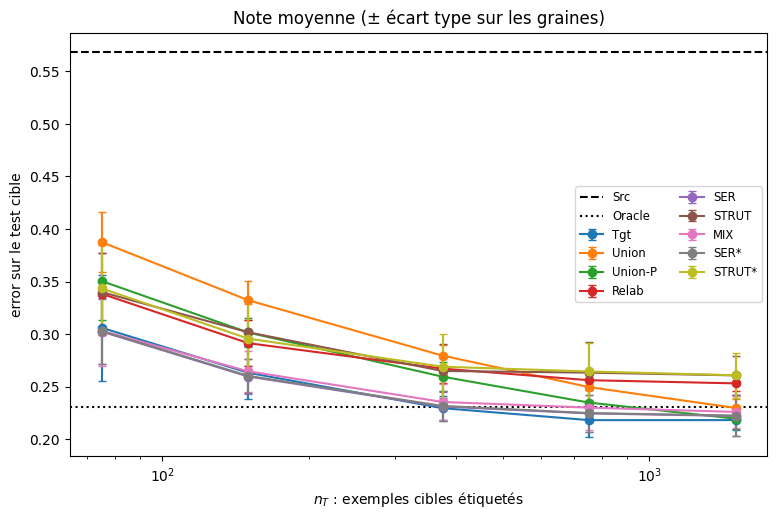

In [5]:
Image(RESULTS / "S6_scores.png")

In [6]:
def by_budget(note):
    """Moyenne sur les 20 graines, par méthode et budget ; Src et Oracle dans « sans budget »."""
    t = results.fillna({"n_T": 0}).pivot_table(index="method", columns="n_T", values=note, aggfunc="mean")
    return t.rename(columns={0: "sans budget"}).round(3)

by_budget("error")

n_T,sans budget,75.0,150.0,376.0,752.0,1504.0
method,,,,,,
MIX,NaN,0.303,0.265,0.236,0.230,0.226
Oracle,0.231,NaN,NaN,NaN,NaN,NaN
Relab,NaN,0.338,0.291,0.267,0.256,0.253
SER,NaN,0.303,0.260,0.231,0.225,0.222
SER*,NaN,0.303,0.260,0.232,0.225,0.223
STRUT,NaN,0.340,0.302,0.265,0.263,0.261
STRUT*,NaN,0.344,0.296,0.269,0.265,0.261
Src,0.568,NaN,NaN,NaN,NaN,NaN
Tgt,NaN,0.306,0.263,0.230,0.218,0.218


**Lecture.**
- **Tgt** (apprendre sur la cible seule) descend de 0,306 avec 75 fenêtres à **0,218 avec 752**, puis ne progresse plus (0,218 avec 1 504). Un plateau d'environ 22 % : ensuite, ce sont les utilisateurs inconnus qui limitent, pas le nombre d'étiquettes.
- **SER et SER\*** suivent Tgt de très près à tous les budgets (0,303 contre 0,306 à 75 ; 0,222 contre 0,218 à 1 504), et **MIX** à moins de 1,2 point.
- **Union et Union-P** partent de très loin (0,388 et 0,351 à 75) et rejoignent Tgt quand le budget grandit (0,220 pour Union-P à 1 504) : les données source gênent d'abord, puis ne coûtent plus rien.
- **STRUT, STRUT\* et Relab** restent de 3 à 5 points derrière Tgt à tous les budgets.
- **Oracle** (toute la réserve, 15 191 fenêtres) fait 0,231 : **moins bien que Tgt** à partir de 752 fenêtres. Ici, Oracle n'est donc pas un plancher. Notre hypothèse, non vérifiée : avec seulement 4 utilisateurs dans la réserve, apprendre sur tout leur historique les rend plus facile à mémoriser, sans aider à généraliser à d'autres personnes.

## 4. Les gains : réels ou dus au hasard ?

Gains appariés graine par graine, en points d'erreur. $G_{Tgt}$ : par rapport à Tgt. $G_{ref}$ : par rapport à la meilleure de Src, Tgt et Union (définition du protocole). L'étoile indique un gain significatif : test de Wilcoxon apparié sur les 20 graines, corrigé par Holm sur les 5 budgets. Un gain **positif** est une amélioration ; un gain négatif significatif est un **transfert négatif**.

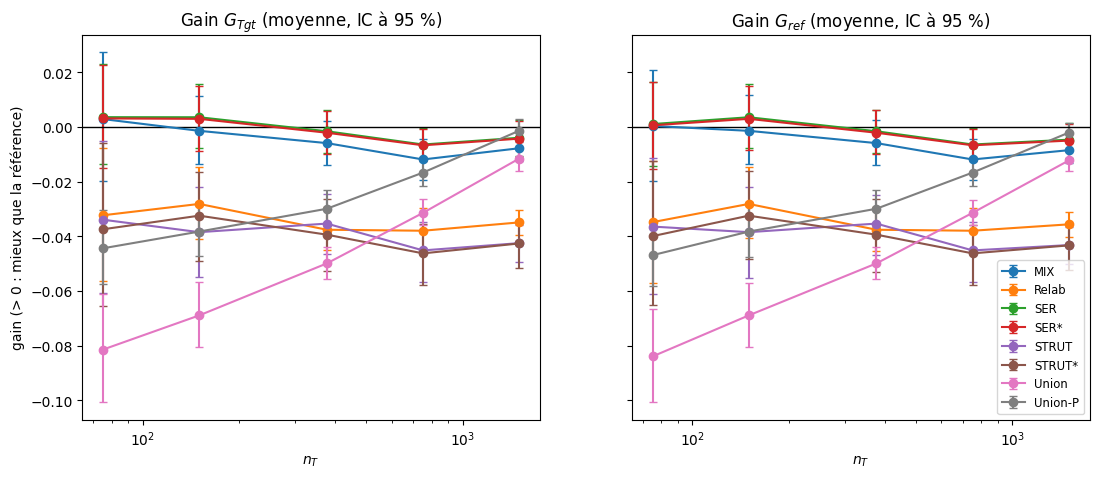

In [7]:
Image(RESULTS / "S6_gains.png")

In [8]:
def with_stars(gain):
    """Gain moyen en points d'erreur ; * : significatif (Wilcoxon, Holm, 5 %)."""
    s = summary.assign(cell=lambda d: (100 * d[f"{gain}_mean"]).round(1).astype(str)
                       + np.where(d[f"{gain}_p_holm"] < 0.05, " *", ""))
    return s.pivot(index="method", columns="n_T", values="cell").drop(index=["Src", "Tgt", "Oracle"])

print("G_Tgt (points d'erreur gagnés sur Tgt)")
display(with_stars("g_tgt"))
print("G_ref (points d'erreur gagnés sur la meilleure de Src, Tgt, Union)")
display(with_stars("g_ref"))

G_Tgt (points d'erreur gagnés sur Tgt)


n_T,75.0,150.0,376.0,752.0,1504.0
method,,,,,
MIX,0.3,-0.1,-0.6,-1.2 *,-0.8 *
Relab,-3.2 *,-2.8 *,-3.8 *,-3.8 *,-3.5 *
SER,0.4,0.4,-0.2,-0.6,-0.4
SER*,0.3,0.3,-0.2,-0.7,-0.4
STRUT,-3.4 *,-3.8 *,-3.5 *,-4.5 *,-4.2 *
STRUT*,-3.7 *,-3.2 *,-3.9 *,-4.6 *,-4.3 *
Union,-8.1 *,-6.9 *,-5.0 *,-3.1 *,-1.2 *
Union-P,-4.4 *,-3.8 *,-3.0 *,-1.7 *,-0.1


G_ref (points d'erreur gagnés sur la meilleure de Src, Tgt, Union)


n_T,75.0,150.0,376.0,752.0,1504.0
method,,,,,
MIX,0.0,-0.1,-0.6,-1.2 *,-0.8 *
Relab,-3.5 *,-2.8 *,-3.8 *,-3.8 *,-3.6 *
SER,0.1,0.4,-0.2,-0.6,-0.5
SER*,0.1,0.3,-0.2,-0.7,-0.5
STRUT,-3.6 *,-3.8 *,-3.5 *,-4.5 *,-4.3 *
STRUT*,-4.0 *,-3.2 *,-3.9 *,-4.6 *,-4.3 *
Union,-8.4 *,-6.9 *,-5.0 *,-3.1 *,-1.2 *
Union-P,-4.7 *,-3.8 *,-3.0 *,-1.7 *,-0.2


In [9]:
synth = summary.pivot(index="method", columns="n_T", values="saving").round(2)
synth["budget de croisement"] = summary.groupby("method")["crossover_n_T"].first()
synth.drop(index=["Src", "Tgt", "Oracle"])

n_T,75.0,150.0,376.0,752.0,1504.0,budget de croisement
method,,,,,,
MIX,1.05,0.98,0.85,0.49,0.31,75.0
Relab,NaN,0.63,0.37,0.24,0.13,75.0
SER,1.06,1.10,0.96,0.68,0.39,75.0
SER*,1.05,1.09,0.94,0.67,0.38,75.0
STRUT,NaN,0.54,0.39,0.20,0.11,75.0
STRUT*,NaN,0.59,0.36,0.20,0.11,75.0
Union,NaN,NaN,0.31,0.29,0.25,75.0
Union-P,NaN,0.54,0.44,0.43,0.46,75.0


**Lecture.**
- **Aucune méthode ne gagne de façon significative sur Tgt, à aucun budget.** Les seuls gains positifs sont ceux de SER et SER\* aux deux plus petits budgets et de MIX au plus petit (de 0,3 à 0,4 point), très loin du seuil : ils tiennent dans le bruit.
- **Le transfert négatif est massif et significatif** pour STRUT, STRUT\* et Relab (de −2,8 à −4,6 points à tous les budgets), pour Union (de −8,1 points à 75 fenêtres à −1,2 à 1 504) et pour Union-P (de −4,4 à −0,1, ce dernier n'étant plus significatif). MIX devient significativement moins bon que Tgt à partir de 752 fenêtres.
- **L'économie d'annotation est d'environ 1** pour SER et SER\* (1,06 à 75, 1,10 à 150) : avec 150 fenêtres, SER fait ce que Tgt fait avec 165. C'est dans le bruit, comme le montrent les gains.
- Le **budget de croisement** vaut 75, le plus petit budget testé, pour toutes les méthodes : il n'y a pas de budget en dessous duquel le transfert aide de façon significative.

## 5. Ce qui compte pour l'exploitation : le coût

C'est le retour de MBDA : pour chaque méthode, le temps d'apprentissage, le temps de prédiction pour 1 000 fenêtres, le poids du modèle sauvegardé et le temps pour le recharger. Moyennes sur les graines et les budgets.

In [10]:
cost = timing[["t_fit_mean", "t_predict_per_1000_mean", "size_bytes_mean", "t_load_mean"]].assign(
    size_Mo=lambda d: d.size_bytes_mean / 1e6).drop(columns="size_bytes_mean")
cost.columns = ["apprentissage (s)", "prédiction, 1 000 fenêtres (s)", "rechargement (s)", "poids (Mo)"]
cost.round(3).sort_values("apprentissage (s)")

,apprentissage (s),"prédiction, 1 000 fenêtres (s)",rechargement (s),poids (Mo)
method,,,,
Src,0.000,0.008,0.058,7.321
Tgt,0.313,0.005,0.031,0.579
Relab,1.613,0.051,0.028,5.228
Union-P,2.416,0.006,0.040,6.363
Union,3.283,0.006,0.048,8.085
SER,4.435,0.052,0.028,4.531
SER*,4.439,0.052,0.028,5.526
Oracle,6.643,0.008,0.046,5.959
STRUT*,8.921,0.043,0.024,1.024


**Lecture.**
- **Tgt est la plus légère et la plus rapide** : 0,3 s pour apprendre, 0,6 Mo, 0,005 s pour prédire 1 000 fenêtres.
- **MIX coûte le plus** : 13 s d'apprentissage (elle apprend SER et STRUT), 0,10 s pour 1 000 fenêtres, 5,5 Mo.
- **Les méthodes de Segev prédisent de 9 à 21 fois plus lentement** que Tgt, comme sur S5 : notre implémentation parcourt les arbres en Python.
- **STRUT** met 9 s à apprendre mais produit un petit modèle (1,0 Mo), car elle élague les arbres.
- **Union, Src et Union-P** pèsent le plus (8,1, 7,3 et 6,4 Mo : elles apprennent sur la source, et pour Union et Union-P aussi sur la cible), et **Src** est la plus lente à recharger (0,058 s).
- Aucun de ces coûts n'est un obstacle pratique : tout se charge en moins de 0,06 s et tient en moins de 10 Mo. La question n'est pas le coût, c'est que le transfert n'apporte rien ici.

## 6. Pourquoi le découpage par utilisateur change tout

On apprend Tgt avec 1 504 fenêtres cibles étiquetées (5 graines), puis on le note sur le test de deux façons : un test **tiré au hasard** parmi les fenêtres (stratifié sur les activités), ou un test fait d'**utilisateurs entiers** (le protocole de ce notebook).

In [11]:
n_T, rows = 1504, []
idx = np.arange(len(scn.yt))
reserve_rand, test_rand = train_test_split(idx, test_size=scn.test_frac, stratify=scn.yt, random_state=TEST_SEED)
for seed in range(5):
    for name, res, tst in [("test d'utilisateurs entiers", reserve, test), ("test tiré au hasard", reserve_rand, test_rand)]:
        lab = res[np.random.default_rng(seed).permutation(len(res))[:n_T]]
        model = make_forest(seed).fit(scn.Xt[lab], scn.yt[lab])
        rows.append((name, seed, np.mean(model.predict(scn.Xt[tst]) != scn.yt[tst])))
leak = pd.DataFrame(rows, columns=["découpage", "graine", "erreur"])
leak.groupby("découpage").erreur.agg(["mean", "std"]).round(3)

,mean,std
découpage,,
test d'utilisateurs entiers,0.217,0.005
test tiré au hasard,0.071,0.004


**Lecture.** Avec un test tiré au hasard, Tgt fait **7 %** d'erreur ; avec des utilisateurs jamais vus, **22 %**. Dans le premier cas, des fenêtres voisines d'un même enregistrement se retrouvent des deux côtés : on mesure surtout la capacité à reconnaître quelqu'un qu'on a déjà vu. C'est le chiffre à droite qui correspond à la question posée ici, et c'est pour cela que le moteur découpe par utilisateur.

## 7. S6 face à S1 : un autre décalage, une autre réponse

Gain moyen sur Tgt ($G_{Tgt}$, en points d'erreur) au plus petit et au plus grand budget de chaque scénario. Les scénarios dont les résultats ne sont pas dans `results/` ne sont pas affichés.

In [12]:
def gains_at_extremes(name):
    s = pd.read_csv(RESULTS / f"{name}_summary.csv")
    s = s[~s.method.isin(["Src", "Tgt", "Oracle"])]
    lo, hi = s.n_T.min(), s.n_T.max()
    pick = lambda n: s[s.n_T == n].set_index("method")["g_tgt_mean"] * 100
    return pd.DataFrame({f"{name}, n_T = {lo:.0f}": pick(lo), f"{name}, n_T = {hi:.0f}": pick(hi)})

available = [n for n in ["S1", "S5", "S6"] if (RESULTS / f"{n}_summary.csv").exists()]
pd.concat([gains_at_extremes(n) for n in available], axis=1).round(1)   # G_Tgt, en points d'erreur ou de BER

,"S1, n_T = 108","S1, n_T = 2164","S6, n_T = 75","S6, n_T = 1504"
method,,,,
MIX,7.1,1.4,0.3,-0.8
Relab,7.5,-1.7,-3.2,-3.5
SER,7.3,1.6,0.4,-0.4
SER*,8.7,1.7,0.3,-0.4
STRUT,0.3,-2.7,-3.4,-4.2
STRUT*,0.5,-2.6,-3.7,-4.3
Union,2.2,1.3,-8.1,-1.2
Union-P,9.7,2.1,-4.4,-0.1


**Lecture.** Sur S1 (Letter), six méthodes de transfert sur huit gagnent de façon significative sur Tgt au plus petit budget : +9,7 points pour Union-P, +8,7 pour SER\* et +7,5 pour Relab avec 108 exemples cibles. Sur S6, **rien ne gagne**, et la plupart des méthodes perdent.

| | S1 (Letter) | S6 (HHAR) |
|---|---|---|
| Décalage | découpage sur une variable (`x2bar`) | autre type d'appareil (poignet contre taille) et utilisateurs jamais vus |
| Forêt source sur la cible | — | 57 % d'erreur, 100 % sur la marche |
| Meilleure méthode | Union-P (+9,7 points à 108 exemples) | aucune : SER, SER\* et MIX font jeu égal avec Tgt |
| Relab | +7,5 points à petit budget | −2,8 à −3,8 points à tous les budgets |

Le décalage de S6 est plus profond : les domaines sont parfaitement séparables et la source ne sait pas reconnaître une partie des activités sur la cible. Dans ces conditions, les exemples de la source renseignent mal sur la cible.

## 8. Bilan : que retenir de S6 ?

1. **Sur S6, le transfert n'apporte rien de mesurable.** Aucun gain significatif sur Tgt, à aucun des 5 budgets. SER, SER\* et MIX font jeu égal avec Tgt aux plus petits budgets ; STRUT, Relab, Union et (aux petits budgets) Union-P font significativement moins bien.
2. **La source ne dit presque rien de la cible.** La forêt source se trompe dans 57 % des cas sur les téléphones, et presque autant sur chacun des trois modèles (56 à 61 %) : le problème est le type d'appareil, pas le modèle. Elle ne reconnaît pas la marche (100 % d'erreur).
3. **La bonne façon de noter est par utilisateur.** Avec un test tiré au hasard, Tgt paraît faire 7 % d'erreur ; avec des utilisateurs jamais vus, 22 %. Ce plateau de 22 % est le chiffre à retenir.
4. **Le coût n'est pas le sujet.** Les méthodes de Segev (SER, STRUT, Relab, MIX) sont de 9 à 21 fois plus lentes à la prédiction que Tgt, mais tout reste en dessous de 0,11 s pour 1 000 fenêtres, de 14 s d'apprentissage et de 10 Mo.
5. **Limites.**
   - Il n'y a que **9 utilisateurs** : le test en contient 5 et la réserve 4, tirés une fois pour toutes (graine fixe). Les résultats dépendent de ce tirage.
   - On ne teste que le sens montres vers téléphones.
   - Les variables sont un choix (fenêtres de 2 s, 32 résumés) : d'autres variables pourraient mieux rapprocher les deux domaines.
   - Oracle fait moins bien que Tgt, ce qui reste à expliquer (voir la section 3).